In [1]:
import pandas as pd 


In [2]:
df = pd.read_csv("../data/processed/rotulado_v1.csv")  
df.columns = df.columns.str.lower()                       
df.to_csv("../data/processed/rotulado_v1.csv", index=False, encoding="utf-8")  
df.head()                                                 

,descricao,categoria,fonte,banco
0,Compra no débito - Jujuca Bomboniere Sao Berna...,Alimentação,conta,Inter
1,Compra no débito - Drogaria Sao Paulo 194sao B...,Saúde,conta,Inter
2,Pagamento efetuado - Pagamento Fatura - PESSOA,Outros,conta,Inter
3,Compra no débito - Coffee Break Mandu Ltdsao B...,Alimentação,conta,Inter
4,Pix recebido - PESSOA,Transferência,conta,Inter


In [3]:
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 667 entries, 0 to 666
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   descricao  667 non-null    str  
 1   categoria  667 non-null    str  
 2   fonte      667 non-null    str  
 3   banco      667 non-null    str  
dtypes: str(4)
memory usage: 21.0 KB


In [4]:
df["categoria"]
df["categoria"].value_counts()

categoria
Alimentação      163
Outros           122
Compras          104
Lazer             59
Transferência     55
Mercado           53
Transporte        53
Saúde             32
Assinaturas       13
Moradia            8
Educação           5
Name: count, dtype: int64

<Axes: ylabel='categoria'>

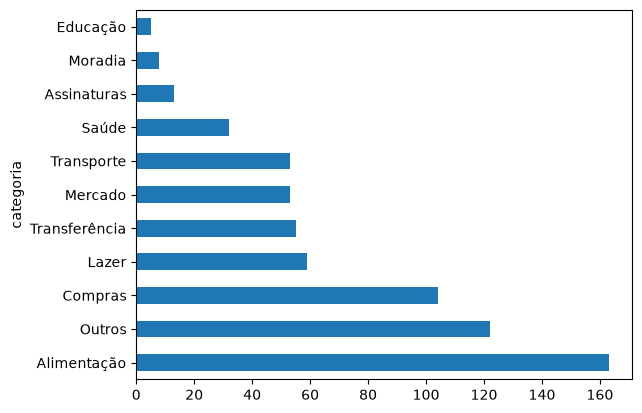

In [5]:
df["categoria"].value_counts().plot(kind="barh")

In [6]:
df[df["categoria"] == "Transporte"]

,descricao,categoria,fonte,banco
22,Compra no débito - Shopping Golden Squaresao B...,Transporte,conta,Inter
27,Compra no débito - Hs Metropole Sbc Sao Bernar...,Transporte,conta,Inter
34,Compra Meio De Transporte - No Estabelecimento...,Transporte,conta,Inter
52,Compra no débito - POSTO MONTE CARLO IGUA,Transporte,conta,Nubank
64,Compra no débito - PAYGO*PHD PARK,Transporte,conta,Nubank
81,Compra no débito - EMV CMT*,Transporte,conta,Nubank
103,PINPAG *AGDESP MUNICIP,Transporte,cartao,Bradesco
104,INPARK,Transporte,cartao,Bradesco
112,StereoCar 01/08,Transporte,cartao,Bradesco
114,SAVOL TOYOTA SBC 01/05,Transporte,cartao,Bradesco


In [7]:
df["tamanho"] = df["descricao"].str.len()
df.groupby("categoria")["tamanho"].mean()

categoria
Alimentação      40.134969
Assinaturas      18.461538
Compras          23.230769
Educação         24.600000
Lazer            22.220339
Mercado          29.226415
Moradia          41.250000
Outros           30.819672
Saúde            30.000000
Transferência    51.054545
Transporte       40.075472
Name: tamanho, dtype: float64

In [8]:
palavras = df["descricao"].str.upper().str.split().explode()
palavras.value_counts().head(15)

descricao
-                  334
NO                 263
COMPRA             210
DÉBITO             202
BRA                202
SAO                160
BERNARDO           113
ESTABELECIMENTO     61
PESSOA              55
PAULO               48
DE                  46
PIX                 36
TRANSFERÊNCIA       32
E                   31
PELO                31
Name: count, dtype: int64

In [9]:
df["fonte"].value_counts()

fonte
cartao    379
conta     288
Name: count, dtype: int64

In [10]:
pag = df['descricao'].str.contains("CORP", regex=False)
df[pag]

,descricao,categoria,fonte,banco,tamanho
559,CORPO E VIDA,Outros,cartao,Itaú,12


In [ ]:
df["tamanho"] = df["descricao"].str.len()

media = df.groupby("categoria")["tamanho"].mean()

media.sort_values(ascending=False)

categoria
Transferência    51.054545
Moradia          41.250000
Alimentação      40.134969
Transporte       40.075472
Outros           30.819672
Saúde            30.000000
Mercado          29.226415
Educação         24.600000
Compras          23.230769
Lazer            22.220339
Assinaturas      18.461538
Name: tamanho, dtype: float64